# 00 · Dataset acquisition & preprocessing (OULAD)

**Dataset:** Open University Learning Analytics Dataset (Kuzilek, Hlosta & Zdrahal, 2017, *Scientific Data* 4:170171),
licensed CC-BY 4.0, mirrored by the UCI Machine Learning Repository (id 349).
It contains **real, anonymised daily virtual-learning-environment (VLE) activity** for 32,593 student enrolments across
7 modules and 4 semesters (2013–2014).

**Why this dataset:** it is the largest openly licensed log of *day-by-day study activity per student per course*. That's
exactly the structure of Milestone's data (student → subjects → daily study).

**Known mismatch, stated up front:**
* OULAD measures **clicks**, not minutes. Every model trained on it uses only *scale-free* features (ratios, shares,
  fractions, or features that are linear in the same unit), so the learnt weights transfer from clicks to minutes. Each notebook
  explains this argument for its model.
* OULAD days are counted from the module start, not calendar days. Weeks are therefore 7-day blocks from the start.
* OULAD has no user-set weekly goals. Where a model needs one, we use a documented proxy.

This notebook downloads the raw data, checks its quality, cleans it, and writes two tidy tables to `data/processed/`.

In [1]:
import json, pathlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = pathlib.Path('data')
PROC = DATA / 'processed'
ASSETS = pathlib.Path('../app/src/main/assets/ml')
ASSETS.mkdir(parents=True, exist_ok=True)
RED, INK, GREY, LINE = '#E11D2A', '#111111', '#8C8C8C', '#DEDEDE'

def is_test(student_id):
    """Deterministic 20% hold-out split by student (no student appears in both sets)."""
    return int(hashlib.md5(str(student_id).encode()).hexdigest(), 16) % 5 == 0

## 1 · Download (skipped if already present)

In [2]:
import urllib.request, zipfile
RAW = DATA / 'oulad_raw'
URL = 'https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip'
if not (RAW / 'studentVle.csv').exists():
    DATA.mkdir(exist_ok=True)
    zpath = DATA / 'oulad.zip'
    urllib.request.urlretrieve(URL, zpath)
    zipfile.ZipFile(zpath).extractall(RAW)
sorted(p.name for p in RAW.iterdir())

['OULAD.names',
 'assessments.csv',
 'courses.csv',
 'studentAssessment.csv',
 'studentInfo.csv',
 'studentRegistration.csv',
 'studentVle.csv',
 'vle.csv']

## 2 · Load with explicit types
OULAD encodes missing values as `?`. The big table (`studentVle`, about 10.6 M rows) is loaded with compact dtypes.

In [3]:
courses = pd.read_csv(RAW / 'courses.csv')
info = pd.read_csv(RAW / 'studentInfo.csv', na_values='?')
reg = pd.read_csv(RAW / 'studentRegistration.csv', na_values='?')
vle = pd.read_csv(RAW / 'vle.csv', na_values='?')
svle = pd.read_csv(RAW / 'studentVle.csv', dtype={
    'code_module': 'category', 'code_presentation': 'category', 'id_student': 'int32',
    'id_site': 'int32', 'date': 'int16', 'sum_click': 'int32'})
for name, df in [('courses', courses), ('studentInfo', info), ('studentRegistration', reg),
                 ('vle', vle), ('studentVle', svle)]:
    print(f'{name:20s} {df.shape}')

courses              (22, 3)
studentInfo          (32593, 12)
studentRegistration  (32593, 5)
vle                  (6364, 6)
studentVle           (10655280, 6)


## 3 · Data-quality audit

In [4]:
audit = pd.DataFrame({
    'missing_registration_date': [reg.date_registration.isna().sum()],
    'missing_unregistration (= did not withdraw)': [reg.date_unregistration.isna().sum()],
    'studentVle exact duplicate rows': [svle.duplicated().sum()],
    'studentVle rows before module start (date<0)': [(svle.date < 0).sum()],
    'sites in studentVle missing from vle.csv': [(~svle.id_site.isin(vle.id_site)).sum()],
}).T.rename(columns={0: 'count'})
audit

,count
missing_registration_date,45
missing_unregistration (= did not withdraw),22521
studentVle exact duplicate rows,787170
studentVle rows before module start (date<0),688988
sites in studentVle missing from vle.csv,0


**About the "duplicates":** OULAD logs one row per *recording event*, not one per (student, site, day). Identical rows are
separate interaction batches that happen to have the same click count. They are not copy errors. The dataset authors define a
student's activity as the **sum** of `sum_click`, so we aggregate by summing instead of dropping rows. The cell below shows how
much the choice matters, for transparency.

In [5]:
dedup_share = 1 - svle.drop_duplicates().sum_click.sum() / svle.sum_click.sum()
print(f'Dropping exact duplicates would remove {dedup_share:.1%} of all clicks; we keep them (summing).')

Dropping exact duplicates would remove 3.2% of all clicks; we keep them (summing).


## 4 · Cleaning rules
1. **Remove navigation-only activity.** `homepage` clicks are course-landing visits, not study, so they're dropped.
2. **Keep only the teaching period:** `0 ≤ date < module_presentation_length`. Pre-start browsing is removed.
3. **Respect withdrawals:** activity on or after `date_unregistration` is removed.
4. **Drop enrolments with too little signal:** fewer than 14 active days, or withdrawn before day 28. These enrolments
   carry almost no weekly pattern, and the app's models only switch on after a similar amount of history.
5. **Winsorise extreme days** at the 99.9th percentile of daily clicks per enrolment. A handful of days with thousands of
   clicks (scripted downloads or bulk resource opening) would otherwise dominate squared-error losses.

In [6]:
types = vle.set_index('id_site').activity_type
svle['activity_type'] = svle.id_site.map(types).astype('category')
print(svle.groupby('activity_type', observed=True).sum_click.sum().sort_values(ascending=False).head(10))

n0 = len(svle)
svle = svle[svle.activity_type != 'homepage']
svle = svle.merge(courses, on=['code_module', 'code_presentation'])
svle = svle[(svle.date >= 0) & (svle.date < svle.module_presentation_length)]
svle = svle.merge(reg[['code_module', 'code_presentation', 'id_student', 'date_unregistration']],
                  on=['code_module', 'code_presentation', 'id_student'], how='left')
svle = svle[svle.date_unregistration.isna() | (svle.date < svle.date_unregistration)]
print(f'rows kept after rules 1-3: {len(svle):,} / {n0:,}')

activity_type
oucontent        11206803
forumng           7973390
quiz              6981240
homepage          6949064
subpage           3411582
resource          1110132
ouwiki             894512
url                566702
oucollaborate      108974
glossary            87962
Name: sum_click, dtype: int32


rows kept after rules 1-3: 8,304,384 / 10,655,280


In [7]:
daily = (svle.groupby(['id_student', 'code_module', 'code_presentation', 'date'], observed=True)
             .sum_click.sum().rename('clicks').reset_index())
enr = (daily.groupby(['id_student', 'code_module', 'code_presentation'], observed=True)
            .agg(active_days=('date', 'nunique')).reset_index()
            .merge(courses, on=['code_module', 'code_presentation'])
            .merge(reg[['code_module', 'code_presentation', 'id_student', 'date_unregistration']],
                   on=['code_module', 'code_presentation', 'id_student'], how='left'))
keep = (enr.active_days >= 14) & (enr.date_unregistration.isna() | (enr.date_unregistration >= 28))
print(f'enrolments kept (rule 4): {keep.sum():,} / {len(enr):,}')
enr = enr[keep].reset_index(drop=True)
enr['enrolment_id'] = np.arange(len(enr), dtype='int32')
# observation window ends at withdrawal if any, else at module end
enr['n_days'] = np.where(enr.date_unregistration.isna(), enr.module_presentation_length,
                         enr.date_unregistration).astype(int)
daily = daily.merge(enr[['id_student', 'code_module', 'code_presentation', 'enrolment_id']],
                    on=['id_student', 'code_module', 'code_presentation'])

enrolments kept (rule 4): 21,471 / 27,889


winsorising 1,424 enrolment-days above 377 clicks (rule 5)


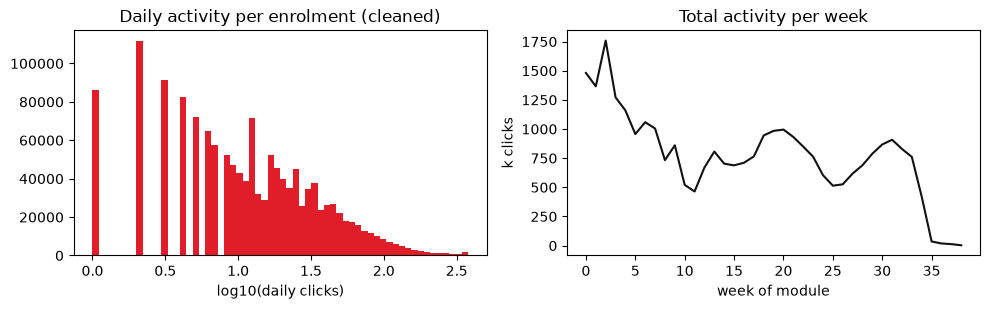

In [8]:
cap = daily.clicks.quantile(0.999)
print(f'winsorising {(daily.clicks > cap).sum():,} enrolment-days above {cap:.0f} clicks (rule 5)')
daily['clicks'] = daily.clicks.clip(upper=cap).astype('float32')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(np.log10(daily.clicks), bins=60, color=RED); ax[0].set_xlabel('log10(daily clicks)')
ax[0].set_title('Daily activity per enrolment (cleaned)')
wk = daily.assign(week=daily.date // 7).groupby('week').clicks.sum()
ax[1].plot(wk.index, wk.values / 1e3, color=INK); ax[1].set_xlabel('week of module'); ax[1].set_ylabel('k clicks')
ax[1].set_title('Total activity per week')
plt.tight_layout(); plt.show()

## 5 · Learners with several concurrent modules (our "subjects")
Milestone users track several subjects at once. In OULAD, a student taking **2–3 modules in the same semester** is the closest
real analogue. Here we build that table for the recommender (notebook 02).

In [9]:
multi = enr.groupby(['id_student', 'code_presentation']).code_module.nunique()
multi = multi[multi >= 2].reset_index()[['id_student', 'code_presentation']]
mm = daily.merge(multi, on=['id_student', 'code_presentation'])
mm = mm.merge(enr[['enrolment_id', 'n_days']], on='enrolment_id')
learners = mm[['id_student', 'code_presentation']].drop_duplicates().reset_index(drop=True)
learners['learner_id'] = np.arange(len(learners), dtype='int32')
mm = mm.merge(learners, on=['id_student', 'code_presentation'])
print(f'{len(learners):,} learners with >=2 concurrent modules, {len(mm):,} learner-module-days')

412 learners with >=2 concurrent modules, 49,370 learner-module-days


## 6 · Save tidy outputs

In [10]:
PROC.mkdir(parents=True, exist_ok=True)
enr[['enrolment_id', 'id_student', 'code_module', 'code_presentation', 'n_days', 'active_days']] \
    .to_parquet(PROC / 'enrolments.parquet', index=False)
daily[['enrolment_id', 'date', 'clicks']].to_parquet(PROC / 'daily_enrolment.parquet', index=False)
mm[['learner_id', 'id_student', 'code_module', 'date', 'clicks', 'n_days']] \
    .to_parquet(PROC / 'daily_multimodule.parquet', index=False)
summary = {
    'enrolments': int(len(enr)), 'students': int(enr.id_student.nunique()),
    'enrolment_days_with_activity': int(len(daily)), 'multi_module_learners': int(len(learners)),
    'winsor_cap_clicks': float(cap),
}
(PROC / 'summary.json').write_text(json.dumps(summary, indent=2))
summary

{'enrolments': 21471,
 'students': 19785,
 'enrolment_days_with_activity': 1425619,
 'multi_module_learners': 412,
 'winsor_cap_clicks': 377.0}